# Best Time Comparison: Sequential vs Parallel vs Cooperative

Run this notebook from the **`visuals/`** folder. It reads **`../results/Best-Scenario-00-99.csv`** and saves charts alongside the notebook in `visuals/`.

The comparisons use only **matched `(stops, seed)` scenarios** completed by all three solvers, so differences in sample sizes do not distort comparisons. Runtime units: **seconds**.

Required packages: `pandas`, `numpy`, `matplotlib` (install with `%pip install pandas numpy matplotlib` if needed).

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

CSV = Path('../results/Best-Scenario-00-99.csv')
if not CSV.exists():
    raise FileNotFoundError(f'CSV not found at {CSV.resolve()}. Run the notebook from the visuals folder.')

df = pd.read_csv(CSV)
methods = ['Sequential', 'Parallel', 'Cooperative']
required = ['model', 'stops', 'seed', 'reward_process_time']

assert not df[required].isna().any().any(), 'Missing values in key columns'

# Remove duplicates, keeping the fastest execution
before = len(df)

df = (
    df.sort_values('reward_process_time', ascending=True)
      .drop_duplicates(subset=['stops', 'seed', 'model'], keep='first')
      .copy()
)

print(f'Removed {before - len(df)} duplicate rows.')

# Retain scenarios tested by all three solvers.
paired = (
    df[df.model.isin(methods)]
    .pivot(
        index=['stops', 'seed'],
        columns='model',
        values='reward_process_time'
    )
    .dropna(subset=methods)[methods]
    .sort_index()
)

counts = paired.groupby(level='stops').size()
means = paired.groupby(level='stops').mean()

print('Matched scenarios by number of stops:')
print(counts.to_string())
display(means.round(4))

Removed 42 duplicate rows.
Matched scenarios by number of stops:
stops
5     100
6     100
7     100
8     100
9     100
10    100
11    100
12    100


model,Sequential,Parallel,Cooperative
stops,,,
5,0.0029,0.3238,0.3296
6,0.0088,0.3415,0.3439
7,0.0519,0.3585,0.3692
8,0.4028,0.4173,0.3841
9,3.0982,0.8672,0.5564
10,13.4374,2.4047,0.8887
11,40.3626,5.7252,1.7039
12,49.6518,6.8444,2.2579


## Figure 1 — Average runtime: grouped vertical bars

For all stop counts, a log-scale y-axis (`LOG_SCALE = True`) makes the very small sequential times visible. Set it to `False` to focus on the larger problems; the bars then use a linear time scale.

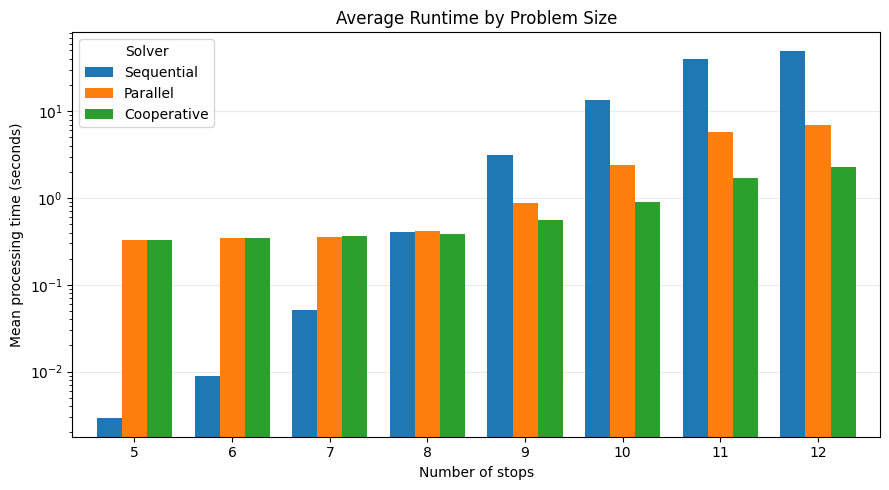

In [10]:
LOG_SCALE = True
ax = means.plot(kind='bar', figsize=(9, 5), width=0.77, rot=0)
ax.set_title('Average Runtime by Problem Size')
ax.set_xlabel('Number of stops')
ax.set_ylabel('Mean processing time (seconds)')
if LOG_SCALE:
    ax.set_yscale('log')
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(title='Solver')
plt.tight_layout()
plt.savefig('images/FB-Runtime.png', dpi=300, bbox_inches='tight')
plt.show()


## Figure 2 — Speedup relative to sequential (higher is better)

Speedup = sequential runtime / solver runtime for the **same seed**. The plotted bars summarize the ratio of matched mean runtimes per stop count. Values above 1 mean faster than sequential; below 1 mean slower. Cooperative and parallel start paying off only when problems are sufficiently expensive.

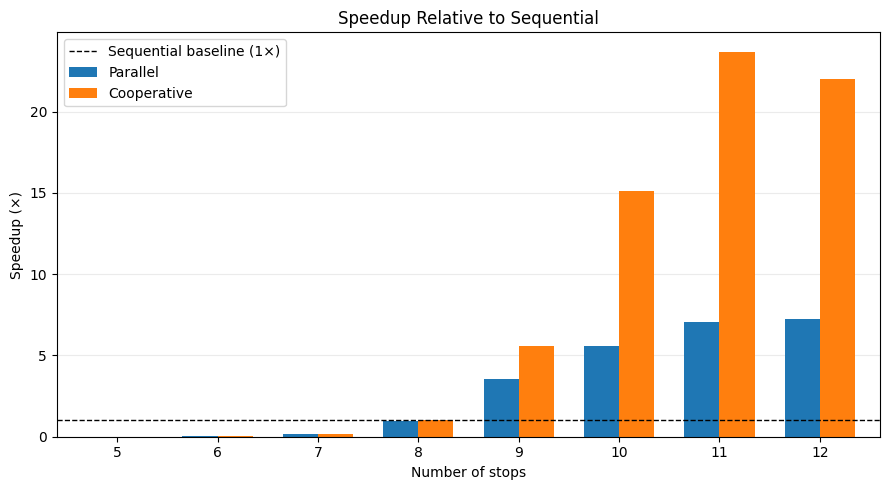

,Parallel,Cooperative
stops,,
5,0.01,0.01
6,0.03,0.03
7,0.14,0.14
8,0.97,1.05
9,3.57,5.57
10,5.59,15.12
11,7.05,23.69
12,7.25,21.99


In [11]:
speedup = pd.DataFrame({
    'Parallel': means['Sequential'] / means['Parallel'],
    'Cooperative': means['Sequential'] / means['Cooperative'],
})
ax = speedup.plot(kind='bar', figsize=(9, 5), rot=0, width=0.7)
ax.axhline(1, color='black', linestyle='--', linewidth=1, label='Sequential baseline (1×)')
ax.set_title('Speedup Relative to Sequential')
ax.set_xlabel('Number of stops')
ax.set_ylabel('Speedup (×)')
ax.legend()
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig('images/FB-Speedup.png', dpi=300, bbox_inches='tight')
plt.show()
display(speedup.round(2))


## Figure 3 — Cooperative runtime variability

A box plot shows the median, interquartile range and outliers for each problem size. Larger boxes or longer whiskers indicate greater variation. Remember that elapsed time variation may be affected by OS scheduling and process startup, not just branch-and-bound search.

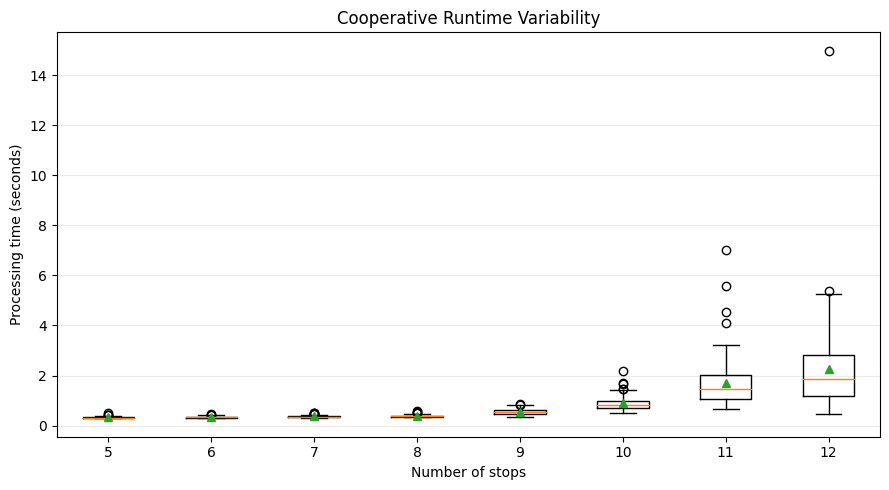

,count,mean,std,median,min,max,cv_percent
stops,,,,,,,
5,100,0.330,0.034,0.320,0.291,0.505,10.211
6,100,0.344,0.033,0.342,0.297,0.453,9.470
7,100,0.369,0.040,0.357,0.318,0.513,10.718
8,100,0.384,0.045,0.372,0.327,0.574,11.753
9,100,0.556,0.105,0.538,0.356,0.861,18.814
10,100,0.889,0.277,0.825,0.504,2.199,31.136
11,100,1.704,0.986,1.447,0.650,7.007,57.873
12,100,2.258,1.740,1.864,0.463,14.974,77.075


In [12]:
# Cooperative Runtime Variability
coop = paired['Cooperative'].reset_index()

stop_sizes = sorted(coop.stops.unique())

samples = [
    coop.loc[coop.stops.eq(s), 'Cooperative'].values
    for s in stop_sizes
]

# Create boxplot
fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(
    samples,
    labels=[str(s) for s in stop_sizes],
    showmeans=True
)

ax.set_title('Cooperative Runtime Variability')
ax.set_xlabel('Number of stops')
ax.set_ylabel('Processing time (seconds)')
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('images/FB-Cooperative-Variability.png', dpi=300, bbox_inches='tight')
plt.show()

# Variability statistics
variability = (
    coop.groupby('stops')['Cooperative']
    .agg(['count', 'mean', 'std', 'median', 'min', 'max'])
)

variability['cv_percent'] = (
    100 * variability['std'] / variability['mean']
)

display(variability.round(3))

## Figure 4 — Search efficiency (optional mechanism evidence)

These counters can help substantiate *why* cooperative pruning helps. `nodes_visited` and `branches_pruned` are distinct metrics and should not be added together or treated as equivalent. The figure compares mean visited nodes for matched scenarios; review how your solvers increment these counters before making strong algorithmic claims.

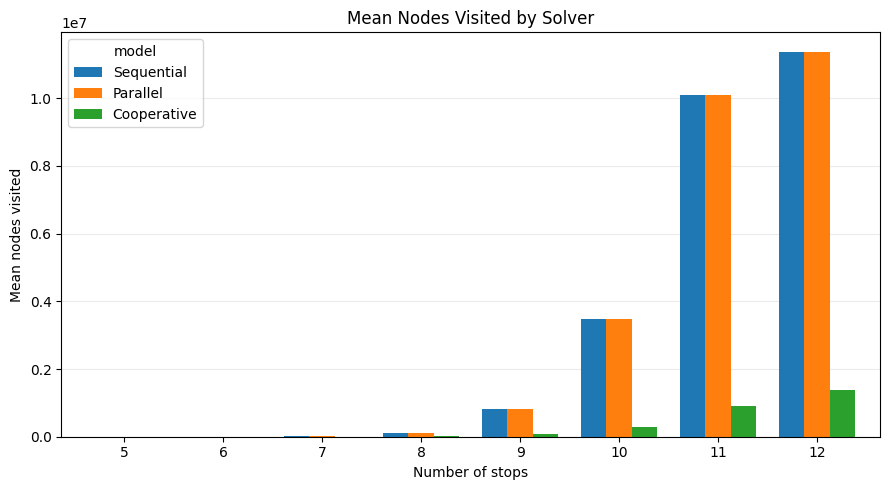

model,Cooperative,Parallel,Sequential
stops,,,
5,68.5,0.0,0.0
6,391.0,0.0,0.0
7,1998.6,0.0,0.0
8,9528.7,0.0,0.0
9,46771.4,0.0,0.0
10,208572.6,0.0,0.0
11,697188.1,0.0,0.0
12,1115197.0,0.0,0.0


In [13]:
valid_pairs = paired.reset_index()[['stops', 'seed']]
search = df.merge(valid_pairs, on=['stops', 'seed'], how='inner')
node_means = (search.groupby(['stops', 'model'])['nodes_visited'].mean()
              .unstack().reindex(columns=methods))
ax = node_means.plot(kind='bar', figsize=(9, 5), rot=0, width=0.77)
ax.set_title('Mean Nodes Visited by Solver')
ax.set_xlabel('Number of stops')
ax.set_ylabel('Mean nodes visited')
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig('images/FB-Nodes_Visited.png', dpi=300, bbox_inches='tight')
plt.show()

if 'branches_pruned' in search:
    display(search.groupby(['stops', 'model'])['branches_pruned'].mean().unstack().round(1))


## Compact paper results table

Use these rounded numbers in your Results section. `n` is the number of scenarios matched across all three solvers.

In [14]:
table = means.copy()
table['Parallel speedup'] = means['Sequential'] / means['Parallel']
table['Cooperative speedup'] = means['Sequential'] / means['Cooperative']
table['Coop vs Parallel (%)'] = 100 * (1 - means['Cooperative'] / means['Parallel'])
table['n'] = counts
print(table.round(3).to_string())
table.to_csv('matched_solver_summary.csv')


model  Sequential  Parallel  Cooperative  Parallel speedup  Cooperative speedup  Coop vs Parallel (%)    n
stops                                                                                                     
5           0.003     0.324        0.330             0.009                0.009                -1.789  100
6           0.009     0.342        0.344             0.026                0.026                -0.682  100
7           0.052     0.359        0.369             0.145                0.140                -2.974  100
8           0.403     0.417        0.384             0.965                1.049                 7.941  100
9           3.098     0.867        0.556             3.572                5.568                35.844  100
10         13.437     2.405        0.889             5.588               15.120                63.042  100
11         40.363     5.725        1.704             7.050               23.689                70.239  100
12         49.652     6.844        2.

### Guidance for publication

- The grouped runtime chart compares **wall-clock time**, which includes parallel-process overhead.
- Speedups are based on the **ratio of matched mean runtimes** at each stop count; values above 1 indicate the solver is faster than sequential.
- Cooperative boxplots show differences **across scenarios**, not run-to-run noise for the same scenario. For execution stability, rerun each fixed seed several times.
- Report your hardware, worker count, Python version, start method and scenario sizes. Add larger stop counts if practical.
- The **nodes visited** chart provides evidence for the impact of cooperative pruning, but node counts across parallel workers may reflect repeated work depending on how your solver logs them.
- Results are exploratory at stop counts with fewer matched scenarios; inspect the `n` column in the summary table.